# 02 · B · Le métier d'abord

*Module 14 « Feature engineering & transformation » · TD du mercredi 21 octobre 2026 · approche B sur quatre, le
cœur de la séance.*

**Ce qu'on fait.** Avant de donner les réservations aux modèles, on fabrique des variables à partir d'hypothèses
métier : une famille par section, l'hypothèse énoncée, le code visible, puis la vérification sur le train. On
choisit ensuite un encodage colonne par colonne et on redresse les variables asymétriques. Les cinq modèles, le
découpage et les métriques restent ceux du notebook 01 : seule la préparation change.

**Les choix de cette approche.**

| Décision | Choix | Pourquoi |
|---|---|---|
| Variables | 30 colonnes construites en sept familles (tableau ci-dessous) + 14 colonnes brutes gardées telles quelles | « une variable dérivée est une hypothèse qu'on peut énoncer » |
| Historique de l'agent et du pays | comptes et taux d'annulation « à date » (`merge_asof` sur la date de clôture) | le passé, rien que le passé : seules les issues connues le jour de la réservation comptent |
| 8 catégorielles à peu de modalités | one-hot, `min_frequency=20`, `handle_unknown="infrequent_if_exist"` | les modalités rares sont regroupées ; une modalité jamais vue ne fait pas planter le service |
| `country`, `agent`, `company` | `TargetEncoder` (validation croisée interne), puis standardisation | des centaines de modalités : une colonne chacune au lieu de centaines |
| `tranche_delai` | `OrdinalEncoder` avec l'ordre imposé | ici l'ordre est réel ; sans `categories=`, il serait alphabétique |
| 11 variables asymétriques | médiane, puis Yeo-Johnson (`PowerTransformer`) | longues traînes à droite, mal digérées par la régression logistique, le kNN et le réseau |
| 21 autres numériques | médiane + indicateur de manquant + standardisation | un taux sans historique vaut NaN : l'absence d'historique devient une colonne |
| Modèles, découpage, métriques | ceux du notebook 01 (`fe_tp.evaluation.evaluer`) | comparer des préparations, pas des modèles |

Les sept familles de variables, et l'hypothèse que chacune met à l'épreuve :

| Famille | Variables | Hypothèse |
|---|---|---|
| Séjour et prix | `nuits`, `part_nuits_week_end`, `personnes`, `enfants`, `famille`, `prix_total`, `prix_par_personne` | une famille organise son voyage et annule moins ; le prix du séjour mesure l'engagement |
| Dates | mois, jour d'arrivée et jour de réservation en (sin, cos) ; `arrivee_week_end` | la saison et le jour de la semaine changent le risque ; décembre est voisin de janvier |
| Délai | `delai`, `tranche_delai` (seuils de 7, 30, 90 et 180 jours) | plus on réserve tôt, plus on a le temps de changer d'avis |
| Historique du client | `nb_resa_passees_client`, `client_connu`, `taux_annul_client` | un client qui a déjà annulé annulera encore |
| Historique à date | `nb_resa_passees_*`, `nb_issues_connues_*`, `taux_annul_passe_*` pour l'agent et le pays | certaines agences et certains pays apportent des clients qui annulent plus |
| Absences | `agent_absent`, `societe_absente` | une réservation sans intermédiaire, ou payée par une entreprise, annule moins |
| Jointure | `continent`, `membre_ue`, `domestique` (référentiel des pays) | les clients du Portugal et ceux venus de loin ne se comportent pas pareil |

**Les outils utilisés.**

- pandas : l'accesseur `.dt` et `np.sin` / `np.cos` pour les cycles (cours 1, slide 12) ; `groupby` et
  `pd.merge_asof` pour l'historique à date (cours 1, slides 13 et 14) ; `pd.cut` pour les tranches métier
  (cours 1, slide 16) ; `merge` avec un référentiel (cours 1, slide 18).
- `SimpleImputer(add_indicator=True)` : l'absence est une information (cours 1, slide 18).
- `OrdinalEncoder(categories=...)` (cours 1, slide 19), `OneHotEncoder` avec `min_frequency` et `handle_unknown`
  (cours 1, slides 20 et 21), `TargetEncoder` (cours 1, slides 22 et 23).
- `PowerTransformer` (Yeo-Johnson, cours 2, slide 8) et `StandardScaler` (cours 2, slide 5).
- `ColumnTransformer`, `make_pipeline` et `joblib.dump` : tout assembler, tout sauvegarder (cours 2, slides 24
  et 25).
- `roc_auc_score` : l'AUC d'une variable prise seule, pour démasquer une fuite (les fuites : cours 1, slides 8
  et 10).
- Le paquet du TD : `charger`, `decouper`, `historique_a_date` (`fe_tp.donnees`), `variables_metier`
  (`fe_tp.variables`), `evaluer` (`fe_tp.evaluation`).

**Ce qu'on regarde à la fin.** Le tableau des cinq modèles (AUC ROC, précision moyenne, exactitude) avec
83 colonnes en sortie de la préparation. Le pipeline du gradient boosting est sauvegardé : le notebook 05 le
compare aux approches A, C et D, puis l'applique à de nouvelles réservations.

## 1. Charger, découper, préparer un tableau vide

Mêmes données et même découpage temporel que dans les autres notebooks : le modèle apprend sur les arrivées
jusqu'au 21 avril 2017 et prédit les suivantes. Les variables seront rangées une à une dans `v`, un tableau vide
qui partage l'index de `df`.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler, TargetEncoder

from fe_tp.donnees import CIBLE, REFERENTIEL_PAYS, SORTIES, charger, decouper, historique_a_date
from fe_tp.evaluation import evaluer
from fe_tp.variables import (ASYMETRIQUES, CATEGORIELLES_B, FORTE_CARDINALITE, NUMERIQUES_B, ORDINALES,
                             TRANCHES_DELAI, variables_metier)

BLEU, ORANGE = "#0B3C7D", "#E8A33D"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = charger()
train, test = decouper(df)
y_train, y_test = train[CIBLE], test[CIBLE]
v = pd.DataFrame(index=df.index)
print(f"{len(df):,} réservations · train {len(train):,} · test {len(test):,}".replace(",", " "))
print(f"taux d'annulation : train {y_train.mean():.1%} · test {y_test.mean():.1%}")

119 208 réservations · train 95 190 · test 24 018
taux d'annulation : train 36.1% · test 41.0%


95 190 réservations pour apprendre (36,1 % d'annulations), 24 018 pour tester (41,0 %). Les variables qui
suivent ne s'apprennent pas : chacune se calcule ligne par ligne, ou à partir du seul passé de la
réservation. On peut donc les calculer sur tout le tableau sans rien faire fuiter. Ce qui s'apprend (médianes,
puissances de Yeo-Johnson, encodages par la cible) attendra le pipeline, ajusté sur le train seul : « fit sur le
train, transform partout ». Les hypothèses, elles, se vérifient sur le train : le test reste au coffre. Une petite
fonction donne l'effectif et le taux d'annulation par modalité, sur le train seulement.

In [3]:
def taux_au_train(colonne):
    return y_train.groupby(v.loc[train.index, colonne]).agg(effectif="size", taux_annulation="mean").round(3)

## 2. Le séjour et le prix

Sept variables, chacune une phrase. Le nombre de nuits et la part du week-end décrivent le séjour ; `personnes`,
`enfants` et `famille` décrivent les voyageurs. `prix_total` est une interaction voulue, `adr × nuits` (cours 1,
slide 17) : c'est ce que le client s'apprête à payer. `prix_par_personne` rapporte le prix d'une nuit au nombre de
voyageurs.

In [4]:
v["nuits"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
v["part_nuits_week_end"] = (df["stays_in_weekend_nights"] / v["nuits"]).fillna(0)
v["personnes"] = df["adults"] + df["children"].fillna(0) + df["babies"]
v["enfants"] = df["children"].fillna(0) + df["babies"]
v["famille"] = (v["enfants"] > 0).astype(int)
v["prix_total"] = df["adr"] * v["nuits"]
v["prix_par_personne"] = df["adr"] / v["personnes"]
taux_au_train("famille")

,effectif,taux_annulation
famille,,
0,88421,0.364
1,6769,0.325


Hypothèse vérifiée, mais modestement : les familles annulent 32,5 % de leurs réservations, contre 36,4 % pour les
autres. Elles ne représentent que 6 769 réservations du train sur 95 190.

Le prix total, maintenant. On découpe le train en cinq groupes de même effectif (`pd.qcut`) pour lire le taux
d'annulation par niveau de prix.

In [5]:
quintiles = pd.qcut(v.loc[train.index, "prix_total"], 5)
y_train.groupby(quintiles, observed=True).agg(effectif="size", taux_annulation="mean").round(3)

,effectif,taux_annulation
prix_total,,
"(-0.001, 120.0]",19070,0.244
"(120.0, 197.0]",19012,0.441
"(197.0, 291.0]",19094,0.396
"(291.0, 453.99]",18977,0.368
"(453.99, 7590.0]",19037,0.356


L'hypothèse « plus c'est cher, plus on s'engage » ne tient pas telle quelle : les séjours les moins chers
(prix total jusqu'à 120) s'annulent le moins (24,4 %), le deuxième quintile le plus (44,1 %), puis le taux
redescend doucement (35,6 % au-delà de 454). La relation n'est pas monotone : une régression logistique la lira mal, un
arbre saura la découper.

## 3. Les dates : des cycles, pas des numéros

Hypothèse : la saison et le jour de la semaine changent le risque d'annulation. Mais en numéro, décembre (12) et
janvier (1) sont à 11 unités l'un de l'autre, alors qu'ils se suivent. On place donc chaque mois, et chaque jour de
la semaine, sur un cercle : deux coordonnées, un sinus et un cosinus (cours 1, slide 12). On le fait pour le mois
d'arrivée, pour le jour d'arrivée et pour le jour où la réservation a été faite.

In [6]:
arrivee, reservation = df["date_arrivee"], df["date_reservation"]
v["mois_sin"] = np.sin(2 * np.pi * arrivee.dt.month / 12)
v["mois_cos"] = np.cos(2 * np.pi * arrivee.dt.month / 12)
v["jour_arrivee_sin"] = np.sin(2 * np.pi * arrivee.dt.dayofweek / 7)
v["jour_arrivee_cos"] = np.cos(2 * np.pi * arrivee.dt.dayofweek / 7)
v["arrivee_week_end"] = (arrivee.dt.dayofweek >= 5).astype(int)
v["jour_resa_sin"] = np.sin(2 * np.pi * reservation.dt.dayofweek / 7)
v["jour_resa_cos"] = np.cos(2 * np.pi * reservation.dt.dayofweek / 7)

Les douze mois sur leur cercle : la distance entre décembre et janvier est la même qu'entre janvier et février.

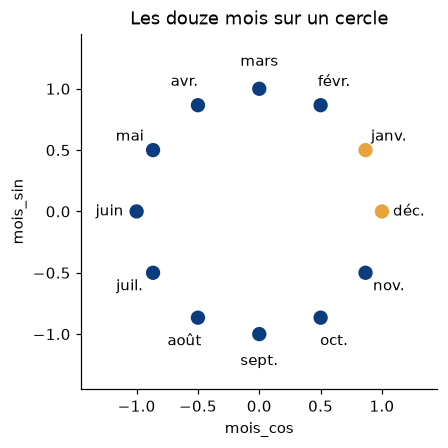

In [7]:
MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
angle = 2 * np.pi * np.arange(1, 13) / 12
fig, ax = plt.subplots(figsize=(4.2, 4.2))
couleurs = [ORANGE if nom in ("déc.", "janv.") else BLEU for nom in MOIS]
ax.scatter(np.cos(angle), np.sin(angle), s=70, color=couleurs)
for nom, x, y in zip(MOIS, np.cos(angle), np.sin(angle)):
    ax.annotate(nom, (1.22 * x, 1.22 * y), ha="center", va="center")
ax.set(xlim=(-1.45, 1.45), ylim=(-1.45, 1.45), aspect="equal", xlabel="mois_cos", ylabel="mois_sin",
       title="Les douze mois sur un cercle")
plt.show()

In [8]:
point = np.c_[np.cos(angle), np.sin(angle)]
print(f"décembre → janvier : {np.linalg.norm(point[11] - point[0]):.3f}")
print(f"janvier → février  : {np.linalg.norm(point[0] - point[1]):.3f}")

décembre → janvier : 0.518
janvier → février  : 0.518


Les deux distances valent 0,518 : sur le cercle, décembre et janvier sont voisins, comme janvier et février.
Vérifions maintenant l'hypothèse sur le jour de la semaine, au train.

In [9]:
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
pd.DataFrame({
    "taux, jour d'arrivée": y_train.groupby(train["date_arrivee"].dt.dayofweek).mean(),
    "taux, jour de réservation": y_train.groupby(train["date_reservation"].dt.dayofweek).mean(),
}).set_axis(JOURS).round(3)

,"taux, jour d'arrivée","taux, jour de réservation"
lundi,0.329,0.315
mardi,0.319,0.336
mercredi,0.340,0.347
jeudi,0.411,0.354
vendredi,0.398,0.489
samedi,0.382,0.299
dimanche,0.316,0.312


Les arrivées du jeudi et du vendredi s'annulent le plus (41,1 % et 39,8 %), celles du dimanche le moins (31,6 %).
Le jour de la réservation compte encore davantage : 48,9 % d'annulations pour les réservations faites un vendredi,
entre 29,9 % et 35,4 % les autres jours. On retrouvera à la section 5 un très gros bloc de réservations faites un
vendredi.

## 4. Le délai, brut et en tranches

Hypothèse : plus on réserve tôt, plus on a le temps de changer d'avis. On garde le délai brut (`delai`, en jours)
et on le découpe en tranches aux seuils métier d'un hôtelier : une semaine, un mois, trois mois, six mois (cours 1,
slide 16). Le `.astype(str)` fait de la tranche une étiquette, que l'on encodera plus loin dans son ordre.

In [10]:
v["delai"] = df["lead_time"]
v["tranche_delai"] = pd.cut(
    df["lead_time"], bins=[-1, 7, 30, 90, 180, np.inf], labels=TRANCHES_DELAI
).astype(str)
taux_au_train("tranche_delai").reindex(TRANCHES_DELAI)

,effectif,taux_annulation
tranche_delai,,
< 1 sem.,17243,0.094
< 1 mois,15920,0.273
< 3 mois,25516,0.375
< 6 mois,18785,0.435
> 6 mois,17726,0.601


L'hypothèse est confirmée, et nettement : 9,4 % d'annulations quand on réserve moins d'une semaine à l'avance,
27,3 % à moins d'un mois, 37,5 % à moins de trois mois, 43,5 % à moins de six mois et 60,1 % au-delà. Le taux
croît à chaque tranche, et les cinq tranches sont bien remplies (de 15 920 à 25 516 réservations).

> 💬 **Question pour la salle.** Pourquoi garder à la fois `delai` et `tranche_delai`, qui disent la même chose ?
>
> *Piste : la tranche parle le langage de l'hôtelier et donne à la régression logistique une marche par tranche ;
> le délai brut garde l'information fine que la tranche efface. Les arbres prendront ce qui leur sert. Le prix à
> payer : deux colonnes très corrélées.*

## 5. L'historique du client

L'hôtel fournit, pour chaque réservation, le nombre de réservations passées du même client, annulées
(`previous_cancellations`) ou non, et s'il s'agit d'un habitué (`is_repeated_guest`). Hypothèse : un client qui a
déjà annulé annulera encore. On en tire trois variables : le nombre de réservations passées, un indicateur
« client connu » et le taux d'annulation passé (NaN quand le client n'a aucun passé : on ne divise pas par zéro).

In [11]:
passees = df["previous_cancellations"] + df["previous_bookings_not_canceled"]
v["nb_resa_passees_client"] = passees
v["client_connu"] = ((passees > 0) | (df["is_repeated_guest"] == 1)).astype(int)
v["taux_annul_client"] = df["previous_cancellations"] / passees.replace(0, np.nan)
tranches_client = pd.cut(v.loc[train.index, "taux_annul_client"], [-0.01, 0, 0.5, 0.99, 1])
y_train.groupby(tranches_client, observed=True).agg(effectif="size", taux_annulation="mean").round(3)

,effectif,taux_annulation
taux_annul_client,,
"(-0.01, 0.0]",2490,0.023
"(0.0, 0.5]",462,0.177
"(0.5, 0.99]",42,0.452
"(0.99, 1.0]",5832,0.996


Hypothèse confirmée… trop bien. Les clients déjà venus sans jamais annuler n'annulent que 2,3 % du temps (2 490
réservations du train), mais ceux dont toutes les réservations passées ont été annulées annulent à 99,6 %, sur
5 832 réservations. Trop beau pour être vrai ? Regardons d'où viennent ces lignes.

In [12]:
deja_annule = v["taux_annul_client"] == 1
print("au train :", deja_annule.loc[train.index].sum(), "· au test :", deja_annule.loc[test.index].sum())
df[deja_annule].groupby(["date_reservation", "agent"]).size().nlargest(3)

au train : 5832 · au test : 3


date_reservation  agent
2014-10-17        1        2013
2015-11-04        19        248
2014-10-17        6         233
dtype: int64

Ces réservations ne sont presque jamais au test : 5 832 au train, 3 au test. Et l'agent « 1 » en a fait 2 013 le
même jour, le vendredi 17 octobre 2014 (l'agent 6, 233 ce jour-là ; l'agent 19, 248 le 4 novembre 2015). Ce n'est
pas le comportement d'un client : ce sont, très probablement, des blocs de chambres réservés pour des groupes,
annulés d'un coup, que l'hôtel a enregistrés comme autant de clients « ayant déjà annulé ». Le motif appartient à la
période du train et ne revient pas au printemps 2017.

> 💬 **Question pour la salle.** Faut-il garder `taux_annul_client` ?
>
> *Piste : elle est connue à la réservation, donc permise ; mais sa force vient d'une poignée de blocs de groupe
> réservés en 2014 et 2015. Vérifier une hypothèse sur le train ne suffit pas : il faut aussi se demander si elle tiendra dans le
> temps. On la garde ici, en sachant qu'elle n'aidera guère au test, et on poserait la question à l'hôtel.*

## 6. L'historique « à date » de l'agent et du pays

Hypothèse : certains agents (agences de voyage) et certains pays apportent des clients qui annulent plus que
d'autres. La variable naturelle est le taux d'annulation passé de l'agent : une agrégation de la cible, donc la
plus dangereuse de toutes (cours 1, slides 13 et 14). Pour une nouvelle réservation, une réservation passée du même
agent ne compte que si son **issue était connue** au moment de la réservation. La frise de la slide 14 :

| lundi 10 h | lundi 14 h | lundi 18 h | mardi 9 h |
|---|---|---|---|
| A est réservée | B est réservée | A est annulée | C est réservée |

Pour B, A ne compte pas encore : son issue est inconnue à 14 h. Pour C, A compte : elle a été annulée la veille.
Ici, on ne connaît que le jour, pas l'heure : une issue compte si sa date de clôture (départ, annulation ou absence)
est **strictement antérieure** au jour de la réservation. D'où une jointure à date, `pd.merge_asof`, que l'on
réécrit d'abord pour l'agent.

In [13]:
closes = df.dropna(subset=["agent"]).groupby(["agent", "date_cloture"])[CIBLE].agg(["size", "sum"])
closes = closes.groupby(level=0).cumsum().reset_index().sort_values("date_cloture")
gauche = df[["reservation_id", "agent", "date_reservation"]].dropna().sort_values("date_reservation")
a_date = pd.merge_asof(gauche, closes, left_on="date_reservation", right_on="date_cloture",
                       by="agent", allow_exact_matches=False)
a_date["taux"] = a_date["sum"] / a_date["size"]
a_date.dropna().sample(3, random_state=0).round(3)

,reservation_id,agent,date_reservation,date_cloture,size,sum,taux
67902,9327,240,2016-09-26,2016-09-25,7821.0,3133.0,0.401
42154,22955,240,2016-02-24,2016-02-23,3633.0,1352.0,0.372
77535,67525,171,2016-12-07,2016-12-03,356.0,109.0,0.306


Lecture : `closes` compte, pour chaque agent et chaque jour de clôture, les réservations closes jusque-là
(`size`) et les annulations parmi elles (`sum`), en cumulé. Pour chaque réservation, `merge_asof` va chercher la
dernière ligne du même agent (`by="agent"`) dont la date de clôture précède la date de réservation ;
`allow_exact_matches=False` exclut les issues du jour même. Première ligne tirée : le 26 septembre 2016,
l'agent 240 avait 7 821 réservations closes (la dernière le 25), dont 3 133 annulées, soit un taux à date de
0,401. La fonction `historique_a_date` du paquet (`src/fe_tp/donnees.py`) fait exactement ce calcul, et compte en
plus les réservations passées. Vérifions.

In [14]:
paquet = historique_a_date(df, "agent").assign(reservation_id=df["reservation_id"])
verif = a_date.merge(paquet, on="reservation_id")
pd.testing.assert_series_equal(verif["taux"], verif["taux_annul_passe_agent"], check_names=False)
print(f"{len(verif):,} réservations avec un agent : même taux à date que historique_a_date".replace(",", " "))

102 928 réservations avec un agent : même taux à date que historique_a_date


Même résultat, NaN compris. On ajoute les trois colonnes de l'agent et les trois du pays, puis on suit un agent
de taille modeste, le numéro 262, sur ses dix premières réservations.

In [15]:
v = v.join(historique_a_date(df, "agent")).join(historique_a_date(df, "country"))
exemple = df.loc[df["agent"] == "262", ["date_reservation", "date_cloture", CIBLE]]
exemple.join(v.filter(like="_agent")).sort_values("date_reservation", kind="stable").head(10)

,date_reservation,date_cloture,is_canceled,nb_resa_passees_agent,nb_issues_connues_agent,taux_annul_passe_agent
115195,2016-09-22,2017-08-06,1,0.0,0.0,NaN
115244,2016-10-14,2017-08-13,0,1.0,0.0,NaN
102528,2016-10-17,2017-05-30,0,2.0,0.0,NaN
72538,2016-10-25,2016-10-27,1,3.0,0.0,NaN
108316,2016-11-08,2017-06-28,0,4.0,1.0,1.0
106559,2016-12-28,2016-12-28,1,5.0,1.0,1.0
106552,2017-01-03,2017-01-26,1,6.0,2.0,1.0
108936,2017-01-26,2017-07-03,0,7.0,2.0,1.0
108937,2017-01-26,2017-07-03,0,7.0,2.0,1.0
107237,2017-02-14,2017-02-14,1,9.0,3.0,1.0


À sa cinquième réservation (8 novembre 2016), l'agent 262 en avait fait quatre, mais une seule était close :
celle du 25 octobre, annulée le 27. Son taux à date vaut donc 1,0 ; les trois autres ne seront closes qu'en 2017,
à la fin des séjours. Sur toute la période, cet agent n'annule pourtant que 8 réservations sur 22 (36 %) : une
annulation se sait plus tôt qu'un séjour terminé. Deux détails montrent `allow_exact_matches=False` à l'œuvre :
l'annulation du 28 décembre, faite le jour même de la réservation, ne compte qu'à partir du lendemain
(`nb_issues_connues_agent` passe à 2 le 3 janvier) ; les deux réservations du 26 janvier ne se comptent pas l'une
l'autre (7 réservations passées chacune).

**Le piège** (cours 1, slide 10, cas 2) : calculer le taux de l'agent « sur toute la période », en une ligne,
avec `groupby(...).transform("mean")`. Cette moyenne contient le futur, et la cible de la ligne elle-même. On mesure
l'AUC de chaque taux pris seul comme score (les NaN reçoivent le taux moyen du train), sur le train, sur le test,
et sur les réservations du test dont l'agent en a fait 50 au plus en tout.

In [16]:
scores = pd.DataFrame({"sur toute la période": df.groupby("agent")[CIBLE].transform("mean"),
                       "à date": v["taux_annul_passe_agent"]}).fillna(y_train.mean())
taille_agent = df["agent"].map(df["agent"].value_counts())
lignes = {"train": train.index, "test": test.index,
          "test, agents de 50 réservations au plus": test.index[taille_agent.loc[test.index] <= 50]}
auc = pd.DataFrame(index=list(lignes), columns=scores.columns, dtype=float)
for nom, index in lignes.items():
    auc.loc[nom] = [roc_auc_score(df.loc[index, CIBLE], scores.loc[index, c]) for c in scores]
auc.round(3)

,sur toute la période,à date
train,0.726,0.606
test,0.668,0.628
"test, agents de 50 réservations au plus",0.931,0.539


Le taux « sur toute la période » paraît bien meilleur : 0,726 contre 0,606 au train, 0,668 contre 0,628 au test.
Et pour les petits agents, il atteint 0,931 contre 0,539 : quand un agent n'a que quelques réservations, sa moyenne
sur toute la période contient presque la réponse de chacune. C'est une fuite : en production, on ne connaît ni
l'avenir de l'agent ni l'issue de la réservation qu'on cherche à prédire. Le score à date est plus modeste, mais
c'est le seul qu'on retrouvera le jour où le modèle servira.

## 7. L'absence est une information

Un agent manquant, c'est une réservation sans intermédiaire ; une société manquante, c'est un client qui ne voyage
pas pour une entreprise (cours 1, slide 18). Hypothèse : les réservations directes et celles des entreprises
annulent moins. Les trois taux qui peuvent valoir NaN (`taux_annul_client`, `taux_annul_passe_agent`,
`taux_annul_passe_country`) recevront aussi leur indicateur, ajouté par `SimpleImputer(add_indicator=True)` à la
section 10.

In [17]:
v["agent_absent"] = df["agent"].isna().astype(int)
v["societe_absente"] = df["company"].isna().astype(int)
pd.concat([taux_au_train("agent_absent"), taux_au_train("societe_absente")],
          keys=["agent_absent", "societe_absente"])

effectif  taux_annulation
                agent_absent                           
agent_absent    0                81460            0.385
                1                13730            0.216
societe_absente 0                 5900            0.173
                1                89290            0.373

Les deux hypothèses tiennent : sans agent, on annule 21,6 % du temps, contre 38,5 % avec un agent ; avec une
société, 17,3 %, contre 37,3 % sans. L'absence de société concerne pourtant presque tout le monde (89 290
réservations du train sur 95 190).

## 8. Enrichir par jointure : le référentiel des pays

Le fichier ne donne que le code du pays. On le joint au référentiel `data/referentiels/pays.csv`, écrit pour le TD
(continent, appartenance à l'Union européenne en 2017), et on ajoute un indicateur « client domestique »
(Portugal). Hypothèse : un client du pays réserve plus facilement, et annule plus facilement, qu'un client venu de
loin. `how="left"` garde toutes les réservations ; un code absent du référentiel devient « inconnu ».

In [18]:
pays = pd.read_csv(REFERENTIEL_PAYS)
jointure = df[["country"]].merge(pays, left_on="country", right_on="code_pays", how="left")
v["continent"] = jointure["continent"].fillna("inconnu").to_numpy()
v["membre_ue"] = jointure["membre_ue_2017"].fillna(0).astype(int).to_numpy()
v["domestique"] = (df["country"] == "PRT").astype(int)
print(len(pays), "pays au référentiel ·", f"{len(jointure):,} lignes après la jointure".replace(",", " "))
pd.concat([taux_au_train("continent"), taux_au_train("domestique")], keys=["continent", "domestique"])

177 pays au référentiel · 119 208 lignes après la jointure


effectif  taux_annulation
continent  Afrique                898            0.411
           Amérique du Nord      1529            0.190
           Amérique du Sud       2053            0.337
           Antarctique              2            0.000
           Asie                  3330            0.318
           Europe               86592            0.368
           Océanie                313            0.195
           inconnu                473            0.110
domestique 0                    53872            0.212
           1                    41318            0.555

La jointure ne crée ni ne perd aucune ligne (119 208 avant et après). Les clients portugais annulent 55,5 % de
leurs réservations, contre 21,2 % pour les autres. Parmi les continents bien représentés, l'Amérique du Nord
(19,0 %) et l'Océanie (19,5 %) annulent le moins ; les 473 réservations sans pays (« inconnu ») seulement 11,0 %.
Les 2 réservations de l'« Antarctique » rappellent qu'un référentiel recopie aussi les bizarreries de la saisie :
le one-hot les rangera dans la colonne des modalités rares.

## 9. Les colonnes brutes gardées, et la vérification

On complète avec les colonnes brutes gardées telles quelles : sept catégorielles à peu de modalités, les trois à
forte cardinalité, et quatre numériques. Puis on vérifie que le tableau construit pas à pas est **exactement**
celui que produit `variables_metier`, la fonction du paquet que les notebooks 05 et 06 réutiliseront.

In [19]:
gardees = CATEGORIELLES_B[:-1] + FORTE_CARDINALITE + [
    "adr", "days_in_waiting_list", "total_of_special_requests", "is_repeated_guest"]
for colonne in gardees:
    v[colonne] = df[colonne]
pd.testing.assert_frame_equal(v, variables_metier(df))
print("identique à variables_metier(df) :", v.shape[1], "colonnes ·", f"{len(v):,} lignes".replace(",", " "))

identique à variables_metier(df) : 44 colonnes · 119 208 lignes


Aucune différence : 44 colonnes, dans le même ordre, avec les mêmes valeurs et les mêmes types. Le paquet les
range en cinq groupes, qui recevront chacun leur préparation.

In [20]:
groupes = {"asym": ASYMETRIQUES, "num": NUMERIQUES_B, "cat": CATEGORIELLES_B,
           "forte_card": FORTE_CARDINALITE, "tranche": ORDINALES}
pd.DataFrame({"colonnes": [len(c) for c in groupes.values()],
              "exemples": [", ".join(c[:4]) for c in groupes.values()]}, index=list(groupes))

,colonnes,exemples
asym,11,"delai, adr, prix_total, prix_par_personne"
num,21,"part_nuits_week_end, personnes, enfants, famille"
cat,8,"hotel, meal, market_segment, distribution_channel"
forte_card,3,"country, agent, company"
tranche,1,tranche_delai


In [21]:
X_train_B, X_test_B = v.loc[train.index], v.loc[test.index]

## 10. Encoder et transformer : une préparation par groupe

Le `ColumnTransformer` a cinq branches (cours 1, slides 19 à 23 ; cours 2, slides 7, 8 et 24) :

| Branche | Colonnes | Préparation | Pourquoi |
|---|---|---|---|
| `asym` | 11 | médiane, puis Yeo-Johnson (qui standardise aussi) | longues traînes à droite : délais, prix, comptes |
| `num` | 21 | médiane + indicateur de manquant, puis standardisation | les taux sans historique valent NaN : l'absence devient une colonne |
| `cat` | 8 | one-hot, `min_frequency=20`, `handle_unknown="infrequent_if_exist"` | peu de modalités ; rares et inconnues regroupées |
| `forte_card` | 3 | « absent » pour les manquants, `TargetEncoder`, puis standardisation | 177 pays, 333 agents et 348 sociétés dans le fichier |
| `tranche` | 1 | `OrdinalEncoder` avec l'ordre imposé | « numéroter, c'est inventer un ordre », sauf quand l'ordre existe |

Un détail de version : depuis scikit-learn 1.9, le paramètre `random_state` de `TargetEncoder` est déprécié. On
passe le découpage de la validation croisée interne explicitement, `cv=StratifiedKFold(5, shuffle=True,
random_state=0)` : ce sont les mêmes plis qu'avec l'ancien `TargetEncoder(random_state=0)`, sans avertissement.

In [22]:
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)
plis = StratifiedKFold(5, shuffle=True, random_state=0)
prep = ColumnTransformer([
    ("asym", make_pipeline(SimpleImputer(strategy="median"), PowerTransformer()), ASYMETRIQUES),
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUMERIQUES_B),
    ("cat", ohe, CATEGORIELLES_B),
    ("forte_card", make_pipeline(SimpleImputer(strategy="constant", fill_value="absent"),
                                 TargetEncoder(cv=plis), StandardScaler()), FORTE_CARDINALITE),
    ("tranche", OrdinalEncoder(categories=[TRANCHES_DELAI]), ORDINALES),
])

On l'ajuste sur le train seul (le `TargetEncoder` a besoin de `y_train`), et on compte les colonnes produites par
chaque branche.

In [23]:
prep.fit(X_train_B, y_train)
noms = pd.Series(prep.get_feature_names_out())
print("colonnes créées par l'imputation et le one-hot :")
print(noms[noms.str.contains("missingindicator|infrequent")].str.split("__").str[1].tolist())
noms.str.split("__").str[0].value_counts().rename("colonnes en sortie").to_frame().T

colonnes créées par l'imputation et le one-hot :
['missingindicator_taux_annul_client', 'missingindicator_taux_annul_passe_agent', 'missingindicator_taux_annul_passe_country', 'market_segment_infrequent_sklearn', 'distribution_channel_infrequent_sklearn', 'reserved_room_type_infrequent_sklearn', 'continent_infrequent_sklearn']


,cat,num,asym,forte_card,tranche
colonnes en sortie,44,24,11,3,1


83 colonnes en sortie : les 44 du tableau, moins 8 catégorielles remplacées par 44 colonnes one-hot, plus 3
indicateurs de manquants (un par taux). Quatre colonnes `..._infrequent_sklearn` recueillent les modalités vues
moins de 20 fois au train et, en production, celles qu'on n'a jamais vues.

**Yeo-Johnson, vu de près** (cours 2, slide 8). Pour chaque colonne, `PowerTransformer` apprend sur le train la
puissance λ qui rend la distribution la plus proche d'une cloche, puis standardise. Le délai avant et après :

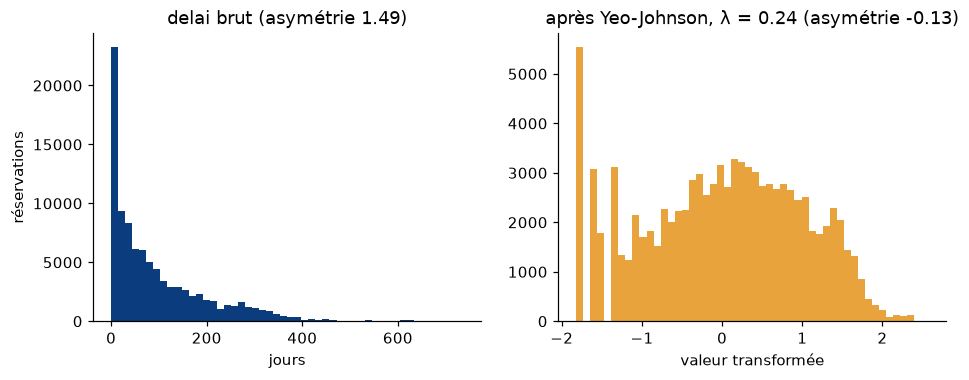

In [24]:
asym = prep.named_transformers_["asym"]
apres = pd.Series(asym.transform(X_train_B[ASYMETRIQUES])[:, 0])
lambdas = pd.Series(asym[-1].lambdas_, index=ASYMETRIQUES)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(X_train_B["delai"], bins=50, color=BLEU)
axes[0].set(title=f"delai brut (asymétrie {X_train_B['delai'].skew():.2f})", xlabel="jours", ylabel="réservations")
axes[1].hist(apres, bins=50, color=ORANGE)
axes[1].set(title=f"après Yeo-Johnson, λ = {lambdas['delai']:.2f} (asymétrie {apres.skew():.2f})",
            xlabel="valeur transformée")
plt.show()

L'asymétrie passe de 1,49 à −0,13 avec λ = 0,24 ; la cloche n'est pas parfaite (le pic des réservations de
dernière minute reste visible), mais la longue traîne a disparu. Les λ appris pour les onze colonnes :

In [25]:
lambdas.round(2).to_frame("λ appris sur le train")

,λ appris sur le train
delai,0.24
adr,0.65
prix_total,0.30
prix_par_personne,0.53
nuits,-0.25
days_in_waiting_list,-6.59
nb_resa_passees_client,-11.25
nb_resa_passees_agent,0.18
nb_issues_connues_agent,0.17
nb_resa_passees_country,0.21


Repères : λ = 1 ne change rien, λ = 0,5 ressemble à une racine carrée, λ = 0 à un logarithme. Le délai, le prix
total et les comptes de l'agent et du pays (λ entre 0,17 et 0,30) sont redressés entre les deux. Un λ très
négatif, comme pour `days_in_waiting_list` (−6,59) ou `nb_resa_passees_client` (−11,25), écrase une colonne faite
presque entièrement de zéros et de quelques valeurs extrêmes.

**`fit(X, y).transform(X)` n'est pas `fit_transform(X, y)`** (cours 1, slide 22). Sur le train, `fit_transform`
encode chaque ligne avec les moyennes apprises sur les quatre autres plis : la ligne ne voit jamais sa propre
cible. `fit` puis `transform` encode chaque ligne avec la moyenne de tout le train, sa propre cible comprise.
Exemple avec l'agent 81, qui a six réservations au train, dont une annulée.

In [26]:
te = TargetEncoder(cv=plis)
agents = X_train_B[["agent"]].fillna("absent")
croise = te.fit_transform(agents, y_train)[:, 0]
direct = te.transform(agents)[:, 0]
print(f"AUC au train : fit_transform {roc_auc_score(y_train, croise):.4f} · fit().transform() "
      f"{roc_auc_score(y_train, direct):.4f}")
ligne = (agents["agent"] == "81").to_numpy()
pd.DataFrame({CIBLE: y_train[ligne], "fit_transform": croise[ligne], "fit().transform()": direct[ligne]}).round(3)

AUC au train : fit_transform 0.7285 · fit().transform() 0.7315


,is_canceled,fit_transform,fit().transform()
9428,0,0.22,0.184
9935,1,0.00,0.184
9941,0,0.22,0.184
9950,0,0.00,0.184
9951,0,0.00,0.184
9955,0,0.22,0.184


Avec `fit().transform()`, les six lignes reçoivent 0,184 : l'annulation de la deuxième est dans son propre
encodage. Avec `fit_transform`, cette ligne annulée reçoit 0,0, car elle est encodée sans elle-même ; les lignes
de son pli reçoivent aussi 0,0, celles des autres plis 0,22. Sur tout le train, l'écart d'AUC reste petit
(0,7285 contre 0,7315), car la plupart des agents ont des centaines de réservations ; il grandit quand les
modalités sont petites. Le pipeline utilise `fit_transform` sur le train : c'est ce que fait `Pipeline.fit`.

## 11. La contamination, mesurée

Cours 1, slide 8 : une contamination, c'est un transformateur qui a vu le test. On encode `agent` et `country` par
la cible, puis on entraîne une régression logistique sur ces deux seules colonnes. Une fois l'encodeur appris sur
le train seul, comme il se doit ; une fois sur le train et le test réunis.

In [27]:
deux = ["agent", "country"]
Xa, Xb = X_train_B[deux].fillna("absent"), X_test_B[deux].fillna("absent")
appris_sur = {"train seul": (Xa, y_train),
              "train + test (contaminé)": (pd.concat([Xa, Xb]), pd.concat([y_train, y_test]))}
contamination = {}
for nom, (X_fit, y_fit) in appris_sur.items():
    encodeur = TargetEncoder().fit(X_fit, y_fit)
    lr = LogisticRegression().fit(encodeur.transform(Xa), y_train)
    contamination[nom] = roc_auc_score(y_test, lr.predict_proba(encodeur.transform(Xb))[:, 1])
pd.Series(contamination).round(3).to_frame("AUC sur le test")

,AUC sur le test
train seul,0.729
train + test (contaminé),0.749


Appris sur le train seul, l'encodage donne une AUC de 0,729 au test ; appris sur le train et le test, 0,749. Les
deux centièmes gagnés ne viennent d'aucun progrès : l'encodeur a lu les annulations du test, et le score mesure en
partie ce qu'il a vu. En production, ce gain disparaît. (On n'utilise ici que `fit`, qui n'a pas besoin de plis.)

## 12. Évaluer les cinq modèles

Mêmes modèles, mêmes réglages et même mesure que dans les autres approches : `evaluer` clone la préparation,
l'enchaîne à chaque modèle dans un `Pipeline`, ajuste le tout sur le train et mesure sur le test. Comptez une à
deux minutes : le réseau de neurones est le plus long.

In [28]:
resultats, pipelines = evaluer("B · variables métier", prep, X_train_B, y_train, X_test_B, y_test)
resultats.drop(columns="approche")

,modele,famille,auc,precision_moyenne,exactitude,nb_variables,duree_s
0,Régression logistique,linéaire,0.851,0.818,0.765,83,8.246
1,kNN,distances,0.853,0.808,0.771,83,12.628
2,Réseau de neurones,réseau,0.881,0.847,0.793,83,49.019
3,Forêt aléatoire,arbres,0.888,0.853,0.791,83,12.626
4,Gradient boosting,arbres,0.888,0.853,0.797,83,8.435


Les deux modèles d'arbres arrivent en tête, à égalité : AUC de 0,888 et précision moyenne de 0,853. Le réseau
de neurones suit de près (0,881), puis le kNN (0,853) et la régression logistique (0,851). Au seuil de 0,5, le
boosting classe correctement 79,7 % des réservations du test, quand un modèle qui prédirait toujours « non
annulée » en classerait 59,0 % (41,0 % d'annulations au test). Côté durée, le réseau est de loin le plus lent
(environ 50 s) ; les quatre autres prennent chacun une dizaine de secondes.

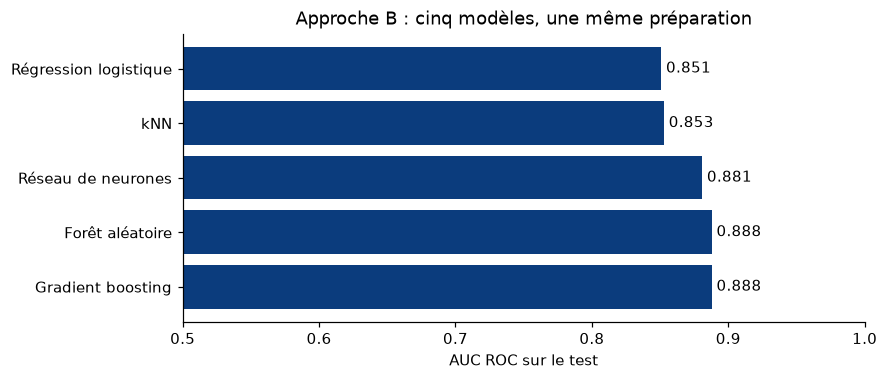

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.4))
barres = ax.barh(resultats["modele"], resultats["auc"], color=BLEU)
ax.bar_label(barres, fmt="%.3f", padding=3)
ax.invert_yaxis()
ax.set(xlim=(0.5, 1), xlabel="AUC ROC sur le test", title="Approche B : cinq modèles, une même préparation")
plt.show()

Avec la même préparation, les cinq modèles tiennent dans 0,037 d'AUC (de 0,851 à 0,888). Le kNN, le plus
sensible au nombre et à l'échelle des colonnes (cours 2, slides 3 et 11), fait jeu égal avec la régression
logistique : 83 colonnes standardisées et redressées donnent à ses distances un sens. Notez ces chiffres : le
notebook 05 les met en regard de ceux des approches A, C et D.

## 13. Sauvegarder le pipeline du gradient boosting

Cours 2, slide 24 : on sauvegarde **l'objet entier**, préparation comprise, avec `joblib.dump`. La production
rejouera exactement les mêmes transformations, avec les médianes, les λ et les encodages appris sur ce train ;
c'est la meilleure protection contre le décalage entre entraînement et production (*training-serving skew*). Le
notebook 05 recharge ce fichier.

In [30]:
chemin, boosting = SORTIES / "modele_B.joblib", pipelines["Gradient boosting"]
joblib.dump(boosting, chemin)
recharge = joblib.load(chemin)
identiques = np.array_equal(recharge.predict_proba(X_test_B), boosting.predict_proba(X_test_B))
print(f"{chemin.name} : {chemin.stat().st_size / 1e6:.1f} Mo · mêmes probabilités après rechargement : {identiques}")

modele_B.joblib : 0.4 Mo · mêmes probabilités après rechargement : True


Le fichier pèse 0,4 Mo : la préparation complète (médianes, λ, modalités du one-hot, encodages par la cible) et
les arbres du boosting. Rechargé, il redonne exactement les mêmes probabilités sur les 24 018 réservations du test.
Attention : il attend en entrée le tableau de `variables_metier`, pas les colonnes brutes du fichier ; le
notebook 05 calculera ces variables pour de nouvelles réservations, et le notebook 06 montrera comment servir
l'historique à date en production.

## 14. À discuter

> 💬 **Question pour la salle.** Le taux d'annulation à date de l'agent n'est-il pas, lui aussi, un encodage par la
> cible ?
>
> *Piste : si. C'est la moyenne de la cible par modalité, comme `TargetEncoder`, mais calculée dans le temps : elle
> ne voit que les issues déjà connues. `TargetEncoder` se protège autrement, par validation croisée ; il ne sait
> rien du temps, d'où l'intérêt d'avoir les deux.*

> 💬 **Question pour la salle.** Quelle variable proposeriez-vous en plus ? Énoncez l'hypothèse avant la formule.
>
> *Piste : les jours fériés et les vacances scolaires portugaises ; l'écart du prix au prix médian de la même
> chambre le même mois (médiane apprise sur le train) ; le nombre de réservations faites le même jour par le même
> agent (un bloc de groupe) ; le nombre de jours depuis la dernière réservation de l'agent.*

## À retenir

- **Une variable dérivée est une hypothèse qu'on peut énoncer**, et qu'on vérifie sur le train. Certaines tiennent
  nettement (le délai : de 9,4 % à 60,1 % d'annulations selon la tranche), d'autres pas telles quelles (le prix
  total), d'autres trop bien (`taux_annul_client` : 99,6 % sur un motif de groupes absent du test).
- **Le passé, rien que le passé.** Une agrégation de la cible se calcule à date, sur les seules issues connues
  (`merge_asof` sur la date de clôture). Calculé sur toute la période, le taux de l'agent affiche 0,931 d'AUC sur
  les petits agents au lieu de 0,539 : une fuite qu'aucune production ne reproduira.
- **Fit sur le train, transform partout.** Un `TargetEncoder` qui a vu le test gagne deux centièmes d'AUC (0,749
  contre 0,729) sans rien apprendre ; et sur le train, `fit_transform` (validation croisée interne) n'est pas
  `fit().transform()`.
- **Un encodage par colonne** : one-hot pour les petites cardinalités, encodage par la cible pour les centaines de
  modalités, ordinal quand l'ordre est réel ; Yeo-Johnson pour les longues traînes. Au total, 83 colonnes.
- **Le résultat** : arbres en tête (AUC 0,888), réseau à 0,881, kNN à 0,853 et régression logistique à 0,851. Le
  pipeline complet du boosting est sauvegardé dans `output/modele_B.joblib` pour le notebook 05.